<a href="https://colab.research.google.com/github/stivenjosez/ab-testing-landing-analysis/blob/main/S9_Version_Student_Proyecto_Landing_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import chi2_contingency, levene, ttest_ind

In [ ]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [ ]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [ ]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB



 -No se observa ningun valor nulo ni valores faltantes en ningunlas de las columnas del dataset.

 -La columna de date cuenta con un erro debido a que es una columna de fecha y se encuentra señalada como object o texto.

In [ ]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')

df.dtypes

user_id                   object
date              datetime64[ns]
landing                   object
region                    object
dispositivo               object
traffic_source            object
user_type                 object
converted                  int64
gasto                    float64
dtype: object

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [ ]:
df['user_id'].nunique()

40000

 **Variable `date`**  
Explorar rango de fechas

In [ ]:
# Resumen estadístico
df["date"].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [ ]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [ ]:
# Resumen estadístico
df['gasto'].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [ ]:
# Resumen estadístico de usuarios que se convirtieron
usuarios_convirtio = df[df["converted"] == 1].copy()

usuarios_convirtio.describe()


,converted,gasto
count,5706.0,5706.000000
mean,1.0,65.373668
std,0.0,30.896545
min,1.0,12.120000
25%,1.0,42.950000
50%,1.0,59.860000
75%,1.0,80.370000
max,1.0,303.680000


 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
for col in ["landing", "region", "traffic_source","dispositivo","user_type"]:
    print(f"\n{col}:")
    display(df[col].value_counts(dropna=False))


Conteo de categorías:

landing:


B    20018
A    19982
Name: landing, dtype: int64


region:


Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64


traffic_source:


Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64


dispositivo:


Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64


user_type:


Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


-La gran mayorias de las columnas cuentas con valores esperado, columnas bien escritas y sin espacios adicionales.

-La columna gasto presenta un sesgo positiva a la derecha y valores atípicos (outliers) superiores (máximo de $303.68$ vs. mediana de $59.86$). Esta dispersión refleja el comportamiento habitual del ticket de compra en e-commerce, donde un segmento minoritario realiza transacciones de alto valor.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [ ]:
# Gasto por versión
gasto_A = usuarios_convirtio[usuarios_convirtio['landing'] == "A"]['gasto']
gasto_B = usuarios_convirtio[usuarios_convirtio['landing'] == "B"]['gasto']


# Verificar cantidad de datos que tiene cada grupo
print(len(gasto_A), len(gasto_B))

print("Media A:", round(gasto_A.mean(), 2))
print("Media B:", round(gasto_B.mean(), 2))

2512 3194
Media A: 61.09
Media B: 68.75


In [ ]:
levene_result = levene(gasto_A, gasto_B)

print("p-value de Levene:", levene_result.pvalue)
alpha = 0.05
equal_var = levene_result.pvalue >= alpha

if equal_var:
    test_name = "Student"
else:
    test_name = "Welch"

print("Usaremos:", test_name)
print("equal_var =", equal_var)

p-value de Levene: 6.875301988016449e-08
Usaremos: Welch
equal_var = False


### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe una diferencia estadísticamente significativa en el gasto promedio (gasto) entre los usuarios que interactuaron con la Versión A y los que interactuaron con la Versión B.
- **Hipótesis alternativa (H₁):** Existe una diferencia estadísticamente significativa en el gasto promedio (gasto) entre los usuarios que interactuaron con la Versión A y los que interactuaron con la Versión B

In [ ]:
# Aplicar prueba
ttest_result = ttest_ind(
    gasto_A,
    gasto_B,
    equal_var=False
)



# Visualizar resultados
print(f"Estadístico : {ttest_result.statistic}")
print(f"Valor p: {ttest_result.pvalue}")

Estadístico : -9.48101092267275
Valor p: 3.627602231521493e-21


In [ ]:
if ttest_result.pvalue < alpha:
    print("Decisión: rechazamos H0.")
    print("Hay evidencia de diferencia en el gasto promedio.")
else:
    print("Decisión: no rechazamos H0.")
    print("No encontramos evidencia suficiente de diferencia en el gasto promedio.")

Decisión: rechazamos H0.
Hay evidencia de diferencia en el gasto promedio.


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula ($H_0$), existe evidencia estadística contundente para descartar que la diferencia en el gasto promedio sea producto del azar.

**Interpretación de negocio:**  
Este análisis prueba que cambiar el diseño de la página A a la página B altera el comportamiento de compra de los usuarios de forma positiva. Al obtener un valor $p$ menor al alfa ($0.05$), comprobamos estadísticamente que ambas versiones no se comportan igual. Como el estadístico $t$ dio negativo ($-9.48$), significa que el gasto medio en la página B es superior al de la página A. En conclusión, la página B incrementa el ticket medio de compra, por lo cual es la mejor opción para la empresa.



---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen difere]ncias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe una diferencia estadísticamente significativa en la tasa de conversión entre la Página A y la Página B
- **Hipótesis alternativa (H₁):** Existe una diferencia estadísticamente significativa en la tasa de conversión entre la Página A y la Página B

In [ ]:
# Número de usuarios convertidos por página
tabla = pd.crosstab(
    df["landing"],
    df["converted"]
)

display(tabla)

# Total de usuarios por página
convertidos_por_pagina = tabla[1]  # Columna de convertidos (1)
total_por_pagina = tabla.sum(axis=1)  # Suma por fila (total A y B)

print("Usuarios convertidos por página:\n", convertidos_por_pagina)
print("\nTotal de usuarios por página:\n", total_por_pagina)


converted,0,1
landing,,
A,17470,2512
B,16824,3194


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: 1, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
dtype: int64


In [ ]:
# Aplicar prueba
chi2_result = chi2_contingency(tabla)


# Visualizar resultados
print(f"Estadístico : {round(chi2_result.statistic, 3)}")
print(f"Valor p: {chi2_result.pvalue}")

if chi2_result.pvalue < alpha:
    print("Decisión: rechazamos H0.")
    print("Hay evidencia de asociación entre landing y conversión.")
else:
    print("Decisión: no rechazamos H0.")
    print("No encontramos evidencia suficiente de asociación.")

Estadístico : 93.375
Valor p: 4.327184295434911e-22
Decisión: rechazamos H0.
Hay evidencia de asociación entre landing y conversión.


In [ ]:
pd.crosstab(df["landing"], df["converted"], normalize='index') * 100

converted,0,1
landing,,
A,87.428686,12.571314
B,84.044360,15.955640


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula ($H_0$). El valor $p$ obtenido ($4.33 \times 10^{-22}$) es significativamente inferior al nivel de significancia ($\alpha = 0.05$), por lo que existe evidencia estadística suficiente para afirmar que la tasa de conversión y el tipo de versión de la página no son independientes.  

**Interpretación de negocio:**  
Existe una asociación estadísticamente significativa entre la versión de la landing page (A o B) y la probabilidad de que un usuario convierta. El valor del estadístico Chi-cuadrado ($\chi^2 = 93.375$) confirma que la diferencia observada en las tasas de conversión de la Página A y la Página B no se debe al azar o a fluctuaciones aleatorias del tráfico, sino que la versión de la página impacta de forma directa en el volumen de conversiones generadas.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe una asociación estadísticamente significativa entre la vairable traffic_source y la conversión (converted), las variables son independientes.
- **Hipótesis alternativa (H₁):** Existe una asociación estadísticamente significativa entre la fuente de tráfico (traffic_source) y la conversión (converted) (las variables son dependientes).

In [ ]:
tabla_trafico = pd.crosstab(
    df["traffic_source"],
    df["converted"]
)

display(tabla_trafico)

# Total de usuarios por página
convertidos_por_trafico = tabla_trafico[1]  # Columna de convertidos (1)
total_por_trafico = tabla_trafico.sum(axis=1)  # Suma por fila (total A y B)

print("Usuarios convertidos por trafico:\n", convertidos_por_trafico)
print("\nTotal de usuarios por trafico:\n", total_por_trafico)

converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


Usuarios convertidos por trafico:
 traffic_source
Ads         1759
Email        918
Organic     2480
Referral     549
Name: 1, dtype: int64

Total de usuarios por trafico:
 traffic_source
Ads         11935
Email        6123
Organic     17987
Referral     3955
dtype: int64


In [ ]:
# Aplicar prueba
chi2_result_tr = chi2_contingency(tabla_trafico)


# Visualizar resultados
print(f"Estadístico : {round(chi2_result_tr.statistic, 3)}")
print(f"Valor p: {chi2_result_tr.pvalue}")

if chi2_result_tr.pvalue < alpha:
    print("\nDecisión: Rechazamos H0.")
    print("Conclusión: Existe una asociación estadísticamente significativa entre la fuente de tráfico y la conversión.")
else:
    print("\nDecisión: No rechazamos H0.")
    print("Conclusión: No hay evidencia estadística suficiente de asociación entre la fuente de tráfico y la conversión.")

Estadístico : 8.662
Valor p: 0.0341375947833914

Decisión: Rechazamos H0.
Conclusión: Existe una asociación estadísticamente significativa entre la fuente de tráfico y la conversión.


In [ ]:
pd.crosstab(df["traffic_source"], df["converted"], normalize='index') * 100

converted,0,1
traffic_source,,
Ads,85.261835,14.738165
Email,85.007349,14.992651
Organic,86.212264,13.787736
Referral,86.118837,13.881163


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula ($H_0$). Dado que el valor $p$ obtenido ($0.0341$) es menor que el nivel de significancia $\alpha = 0.05$, existe evidencia estadística suficiente para afirmar que la fuente de tráfico y la conversión no son independientes.

**Interpretación de negocio:**  
El análisis muestra que el comportamiento de conversión varía según el canal de origen. En términos absolutos, el canal Organic aporta el mayor volumen de conversiones ($2,480$), seguido de Ads ($1,759$). En términos relativos, el canal Email lidera la eficiencia con una tasa de conversión del $14.99\%$, mientras que Organic registra un $13.79\%$. Aunque estadísticamente la relación es real, en la práctica la brecha entre el canal de mayor y menor rendimiento es reducida ($\approx 1.2\%$), por lo que las acciones de optimización deberían enfocarse primordialmente en la experiencia del usuario dentro del sitio web.  


## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** No existe una asociación estadísticamente significativa entre el tipo de usuario (user_type) y la conversión (converted) (las variables son independientes).
- **Hipótesis alternativa (H₁):** Existe una asociación estadísticamente significativa entre el tipo de usuario (user_type) y la conversión (converted) (las variables son dependientes).

In [ ]:
tabla_user_type = pd.crosstab(
    df["user_type"],
    df["converted"]
)

display(tabla_user_type)

# Total de usuarios por página
convertidos_por_user_type = tabla_user_type[1]  # Columna de convertidos (1)
total_por_user_type = tabla_user_type.sum(axis=1)  # Suma por fila (total A y B)

print("Usuarios convertidos por trafico:\n", convertidos_por_user_type)
print("\nTotal de usuarios por trafico:\n", total_por_user_type)

converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


Usuarios convertidos por trafico:
 user_type
Nuevo         3738
Recurrente    1968
Name: 1, dtype: int64

Total de usuarios por trafico:
 user_type
Nuevo         26033
Recurrente    13967
dtype: int64


In [ ]:
pd.crosstab(df["user_type"], df["converted"], normalize='index') * 100

converted,0,1
user_type,,
Nuevo,85.641301,14.358699
Recurrente,85.909644,14.090356


In [ ]:
# Aplicar prueba
chi2_result_st = chi2_contingency(tabla_user_type)


# Visualizar resultados
print(f"Estadístico : {round(chi2_result_st.statistic, 3)}")
print(f"Valor p: {chi2_result_st.pvalue}")
if chi2_result_st.pvalue < alpha:
    print("\nDecisión: Rechazamos H0.")
    print("Conclusión: Existe una asociación estadísticamente significativa entre el tipo de usuario y la conversión.")
else:
    print("\nDecisión: No rechazamos H0.")
    print("Conclusión: No hay evidencia estadística suficiente de asociación entre el tipo de usuario y la conversión.")


Estadístico : 0.513
Valor p: 0.4736341272301974

Decisión: No rechazamos H0.
Conclusión: No hay evidencia estadística suficiente de asociación entre el tipo de usuario y la conversión.


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipótesis nula ($H_0$). Dado que el valor $p$ obtenido ($0.4736$) es superior al nivel de significancia estándar ($\alpha = 0.05$), no se cuenta con evidencia estadística suficiente para afirmar que existe una asociación entre el tipo de usuario y la conversión.

**Interpretación de negocio:**  
La probabilidad de conversión de un usuario no depende de su perfil (nuevo o recurrente). Ambos segmentos muestran tasas muy similares (~$14.36\%$ y ~$14.09\%$). Aunque los usuarios nuevos generan más conversiones absolutas, se debe únicamente a que hay mayor volumen de tráfico en ese grupo, no a una mayor propensión a comprar. Por lo tanto, la página tiene el mismo nivel de efectividad para ambos tipos de usuario.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

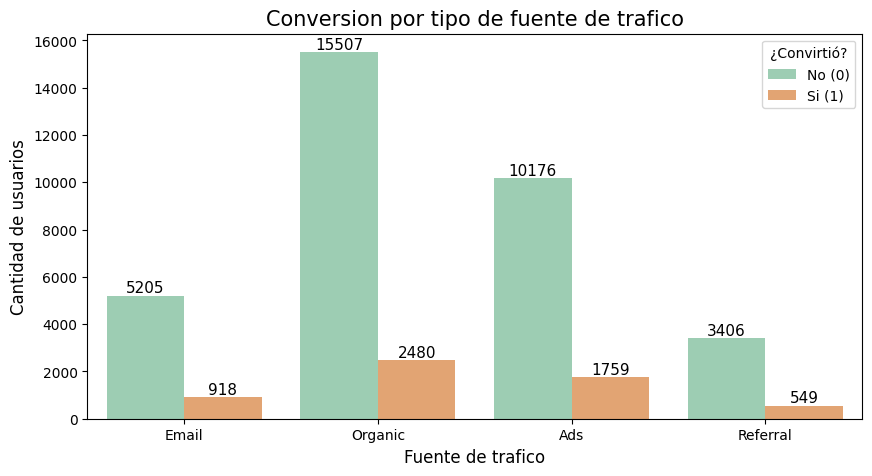

In [ ]:
plt.figure(figsize=(10,5))
ax = sns.countplot(data=df, x='traffic_source', hue='converted', palette=["#95D5B2","#F4A261"])

for bar in ax.patches:
    height = bar.get_height()
    ax.text(x=bar.get_x()+bar.get_width() /2,
            y=height,
            s=height,
            ha='center',
            va='bottom',
            fontsize=11)

plt.title('Conversion por tipo de fuente de trafico', fontsize=15)
plt.xlabel('Fuente de trafico', fontsize=12)
plt.ylabel('Cantidad de usuarios', fontsize=12)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Si (1)'])
plt.show()


El gráfico de barras muestra la distribución absoluta de usuarios según su fuente de tráfico (traffic_source) y su estado de conversión (converted). Se observa que el canal Organic lidera tanto en volumen de tráfico total como en conversiones absolutas ($2,480$ usuarios convertidos), seguido por Ads ($1,759$ convertidos). Por su parte, los canales de Email y Referral registran los menores volúmenes absolutos de conversión ($918$ y $549$ respectivamente), reflejando el peso operativo que aporta cada canal de adquisición al negocio.

In [ ]:
tabla_tc = pd.crosstab(df["traffic_source"], df["converted"], normalize='index') * 100
tabla_tc

converted,0,1
traffic_source,,
Ads,85.261835,14.738165
Email,85.007349,14.992651
Organic,86.212264,13.787736
Referral,86.118837,13.881163


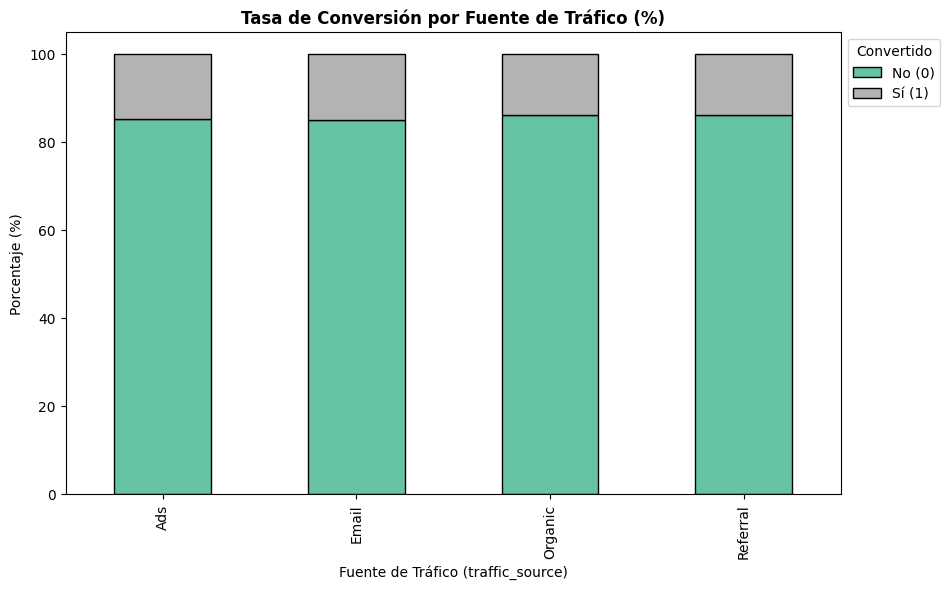

In [ ]:
tabla_tc.plot(kind='bar', stacked=True, figsize=(10,6), colormap='Set2', edgecolor='black')

plt.title('Tasa de Conversión por Fuente de Tráfico (%)', fontsize=12, fontweight='bold')
plt.xlabel('Fuente de Tráfico (traffic_source)', fontsize=10)
plt.ylabel('Porcentaje (%)', fontsize=10)
plt.legend(title='Convertido', labels=['No (0)', 'Sí (1)'], bbox_to_anchor=(1, 1), loc='upper left')
plt.show()


El gráfico de barras apiladas muestra la proporción normalizada en porcentaje (%) de conversión para cada fuente de tráfico (traffic_source). Al observar los datos relativos, las tasas de conversión son sumamente uniformes en todos los canales, oscilando de manera estrecha entre el 13.79% para el tráfico Organic y el 14.99% para Email. Esto respalda visualmente que, a pesar de las diferencias estadísticas formales, el impacto práctico y la efectividad de conversión son prácticamente idénticos sin importar el canal de origen.

### Relación entre el tipo de usuario y la conversión

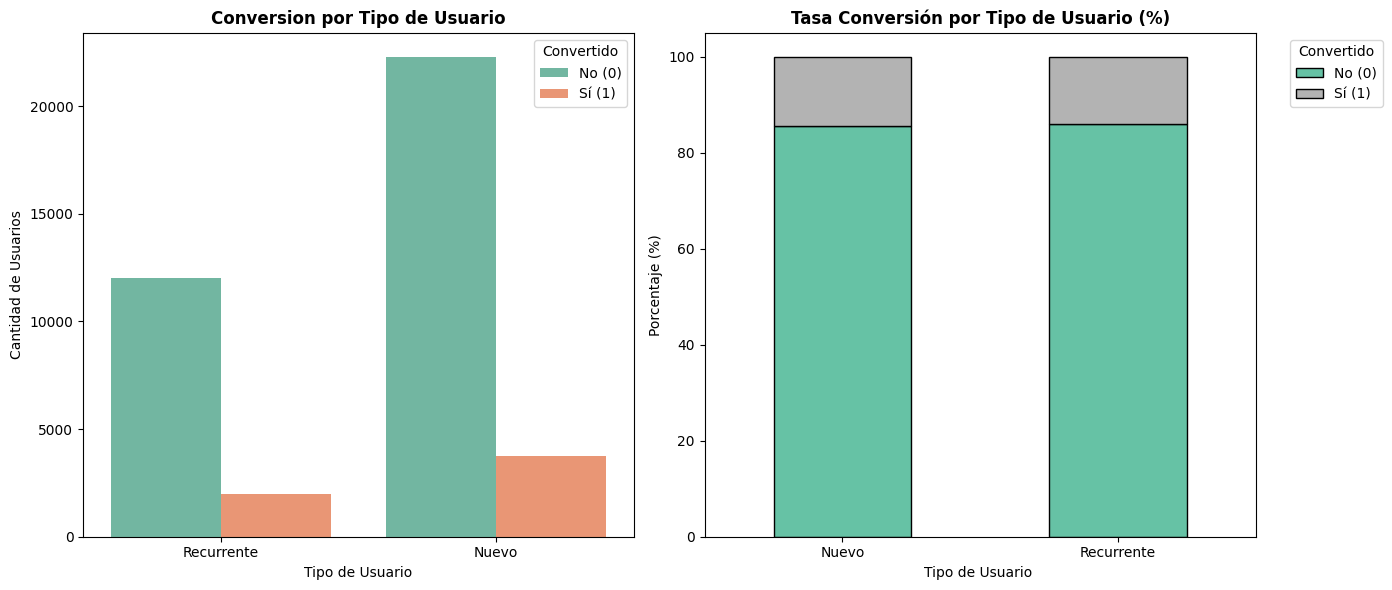

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.countplot(
    data=df,
    x='user_type',
    hue='converted',
    palette='Set2',
    ax=axes[0]
)
axes[0].set_title('Conversion por Tipo de Usuario', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tipo de Usuario', fontsize=10)
axes[0].set_ylabel('Cantidad de Usuarios', fontsize=10)
axes[0].legend(title='Convertido', labels=['No (0)', 'Sí (1)'])

prop_df_user = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100
prop_df_user.plot(
    kind='bar',
    stacked=True,
    ax=axes[1],
    colormap='Set2',
    edgecolor='black'
)

axes[1].set_title('Tasa Conversión por Tipo de Usuario (%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tipo de Usuario ', fontsize=10)
axes[1].set_ylabel('Porcentaje (%)', fontsize=10)
axes[1].legend(title='Convertido', labels=['No (0)', 'Sí (1)'], bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1].tick_params(axis='x', rotation=0)


plt.tight_layout()
plt.show()

**Hallazgo del Gráfico Izquierdo: Cantidad Absoluta de Usuarios.**

El grupo de usuarios Nuevos concentra la mayor parte del tráfico y de las conversiones absolutas de la plataforma, registrando un total de $26,033$ usuarios de los cuales $3,738$ concretaron la conversión. En contraste, los usuarios Recurrentes presentan un volumen menor, con $13,967$ usuarios totales y $1,968$ conversiones absolutas, lo que refleja cuantitativamente que la captación global depende principalmente del flujo constante de usuarios nuevos.


**Hallazgo del Gráfico Derecho: Proporción de Conversión (%).**

Al normalizar los datos al $100\%$, las barras apiladas muestran una distribución prácticamente idéntica en la efectividad de conversión de ambos perfiles. Los usuarios Nuevos presentan una tasa de conversión del $14.36\%$ frente al $14.09\%$ de los usuarios Recurrentes, demostrando visualmente que la probabilidad de conversión de la página es equivalente sin importar si el usuario es nuevo o recurrente.  

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- La prueba de Welch confirmó una diferencia estadísticamente significativa en el gasto promedio entre versiones ($t = -9.48, p \approx 0$).
- La variante B incrementa de manera sustancial el valor monetario aportado por cada comprador.
- **Interpretación:**
- El cambio implementado maximiza con éxito el ticket de compra, elevando el valor financiero por cliente.

<br>

**Tasa de conversión:**
- La prueba Chi-cuadrada evidenció una asociación altamente significativa entre la versión de la página y la conversión.
- La variante ganadora supera de forma notable la proporción de visitantes que logran concretar una compra.
- **Interpretación:**
- Las mejoras de diseño o usabilidad persuaden con mayor eficacia a la audiencia, disparando el rendimiento comercial del sitio.

---

#### 📊 **Segmentación por fuente de tráfico**
- Existe una asociación estadística formal ($p = 0.0341$), destacando a Organic en volumen absoluto y a Email en tasa relativa (~$14.99\%$), aunque con una brecha práctica mínima ($\approx 1.2\%$).
- **Interpretación:**
- El rendimiento de conversión es homogéneo entre canales; la adquisición de usuarios funciona de manera estable sin depender drásticamente de un único origen.

 ---

#### 📊 **Segmentación por tipo de usuario**
- No se encontró una asociación estadísticamente significativa ($p = 0.4736$); los usuarios nuevos y recurrentes muestran tasas de conversión prácticamente idénticas (~$14.36\%$ vs. ~$14.09\%$).
- **Interpretación:**
- La plataforma es igualmente efectiva para ambos perfiles; el mayor volumen de conversiones en usuarios nuevos responde solo al mayor tráfico recibido, no a una mayor propensión de compra.
  

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:**
- Desplegar de forma definitiva la versión ganadora del test A/B en todo el tráfico para asegurar el incremento sostenido de la conversión y el gasto promedio.
-  se recomienda implementar incentivos por primera compra (como un cupón de bienvenida) para los usuarios nuevos, aprovechando que este segmento representa el mayor volumen de tráfico del sitio ($26,033$ visitantes).